========== Summary ==========
True repair times: [30, 68, 113, 146, 170]
Kalman estimated repair times: []
Number of true repairs: 5
Number of KF repairs: 0


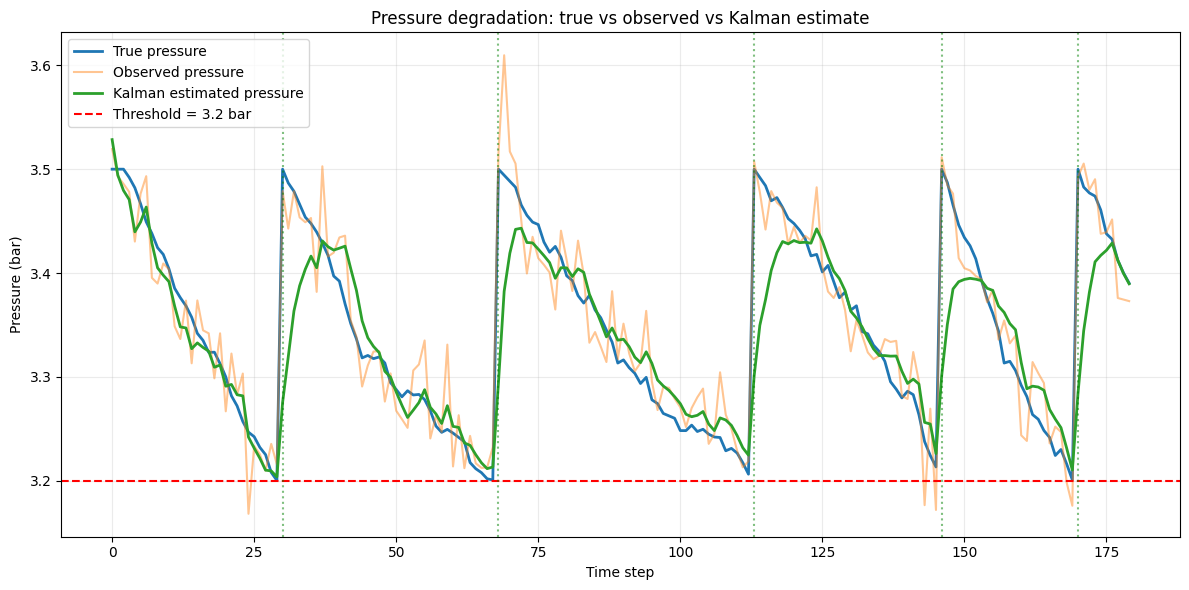

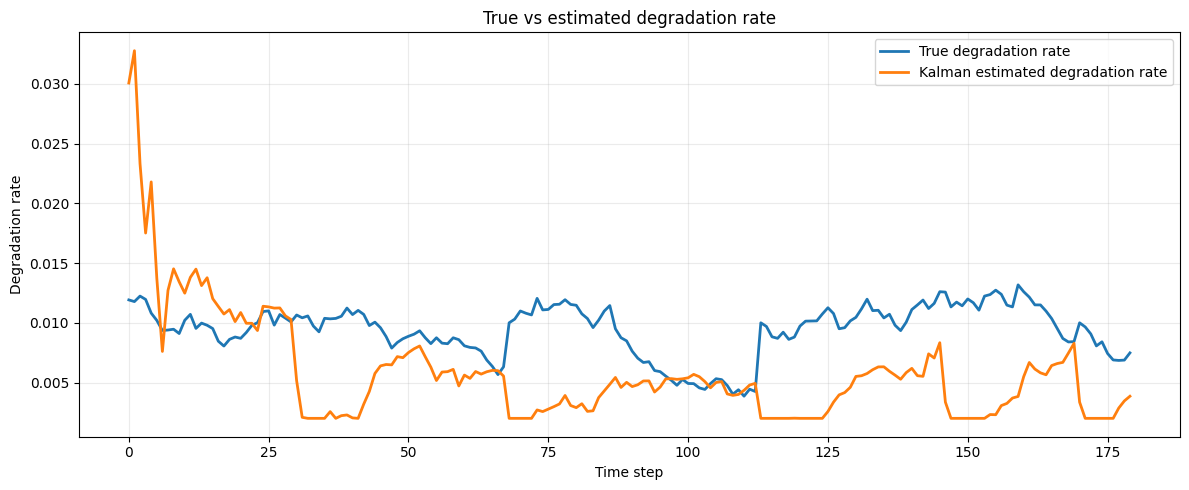


Forecast from final estimated state:
   future_step  forecast_pressure  forecast_rate
0            1           3.385758       0.003851
1            2           3.381907       0.003851
2            3           3.378056       0.003851
3            4           3.374206       0.003851
4            5           3.370355       0.003851
5            6           3.366504       0.003851
6            7           3.362653       0.003851
7            8           3.358802       0.003851
8            9           3.354951       0.003851
9           10           3.351100       0.003851


In [ ]:
# no separated at each cr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Complete Simulation + Kalman Filter Example
# ------------------------------------------------------------
# Scenario:
# - Pressure starts from an initial value and overall decreases.
# - Degradation rate is hidden and estimated by Kalman filter.
# - Only pressure is observed.
# - When pressure reaches the threshold, maintenance is triggered.
# - After maintenance, pressure resets and a new degradation segment starts.
# ============================================================

np.random.seed(42)

# ============================
# 1. Parameters
# ============================
T = 180                      # total time steps
DT = 1.0                     # time step size
THRESHOLD = 3.2              # maintenance threshold (bar)
RESET_PRESSURE = 3.5         # pressure after maintenance (bar)
MIN_RATE = 0.002             # lower bound to keep overall downward trend
RESET_RATE = 0.010           # rate after maintenance reset

# Ground truth process noise
SIGMA_P_PROCESS = 0.008      # process noise on pressure
SIGMA_R_PROCESS = 0.0006     # process noise on degradation rate

# Measurement noise
SIGMA_MEAS = 0.03            # sensor noise on observed pressure

# Kalman filter covariance settings
Q = np.array([
    [SIGMA_P_PROCESS**2, 0.0],
    [0.0, SIGMA_R_PROCESS**2]
])
R = np.array([[SIGMA_MEAS**2]])

# State-space model
# x_k = [pressure_k, rate_k]^T
A = np.array([
    [1.0, -DT],
    [0.0,  1.0]
])
H = np.array([[1.0, 0.0]])
I = np.eye(2)

# ============================
# 2. Initial values
# ============================
# True initial state
x_true = np.array([[3.80],   # true pressure
                   [0.012]]) # true degradation rate

# Kalman initial estimate
x_hat = np.array([[3.76],    # estimated pressure
                  [0.010]])  # estimated degradation rate

# Initial covariance
P = np.array([
    [0.02, 0.0],
    [0.0,  0.002]
])

# ============================
# 3. Storage
# ============================
records = []
true_repair_times = []
kf_repair_times = []
segment_id = 0

# ============================
# 4. Main simulation loop
# ============================
for k in range(T):

    # --------------------------------------------------------
    # 4.1 Simulate ground truth dynamics
    # --------------------------------------------------------
    w = np.random.multivariate_normal(mean=[0.0, 0.0], cov=Q).reshape(-1, 1)
    x_true = A @ x_true + w

    # Keep degradation rate nonnegative so pressure keeps an overall downward trend
    x_true[1, 0] = max(float(x_true[1, 0]), MIN_RATE)

    # Prevent unrealistic pressure above reset level
    x_true[0, 0] = min(float(x_true[0, 0]), RESET_PRESSURE)

    true_repair_flag = 0

    # True maintenance trigger based on true pressure
    if x_true[0, 0] <= THRESHOLD:
        true_repair_flag = 1
        true_repair_times.append(k)
        segment_id += 1

        # Reset true state after maintenance
        x_true[0, 0] = RESET_PRESSURE
        x_true[1, 0] = max(float(x_true[1, 0]), RESET_RATE)

    # --------------------------------------------------------
    # 4.2 Generate measurement (only pressure is observed)
    # --------------------------------------------------------
    v = np.random.normal(loc=0.0, scale=SIGMA_MEAS, size=(1, 1))
    z = H @ x_true + v

    # --------------------------------------------------------
    # 4.3 Kalman filter predict step
    # --------------------------------------------------------
    x_pred = A @ x_hat
    P_pred = A @ P @ A.T + Q

    # --------------------------------------------------------
    # 4.4 Kalman filter update step
    # --------------------------------------------------------
    y = z - H @ x_pred
    S = H @ P_pred @ H.T + R
    K = P_pred @ H.T @ np.linalg.inv(S)

    x_hat = x_pred + K @ y
    P = (I - K @ H) @ P_pred

    # Keep estimated rate nonnegative as well
    x_hat[1, 0] = max(float(x_hat[1, 0]), MIN_RATE)

    kf_repair_flag = 0

    # Estimated maintenance trigger based on Kalman estimated pressure
    if x_hat[0, 0] <= THRESHOLD:
        kf_repair_flag = 1
        kf_repair_times.append(k)

        # Reset estimator after estimated maintenance
        x_hat[0, 0] = RESET_PRESSURE
        x_hat[1, 0] = max(float(x_hat[1, 0]), RESET_RATE)
        P = np.array([
            [0.02, 0.0],
            [0.0,  0.002]
        ])

    # --------------------------------------------------------
    # 4.5 Save results
    # --------------------------------------------------------
    records.append({
        'time': k,
        'segment_id': segment_id,
        'pressure_true': float(x_true[0, 0]),
        'rate_true': float(x_true[1, 0]),
        'pressure_obs': float(z[0, 0]),
        'pressure_est': float(x_hat[0, 0]),
        'rate_est': float(x_hat[1, 0]),
        'true_repair_trigger': true_repair_flag,
        'kf_repair_trigger': kf_repair_flag
    })

# ============================
# 5. Convert to DataFrame
# ============================
df = pd.DataFrame(records)

# ============================
# 6. Print summary
# ============================
print('========== Summary ==========')
print('True repair times:', true_repair_times)
print('Kalman estimated repair times:', kf_repair_times)
print('Number of true repairs:', len(true_repair_times))
print('Number of KF repairs:', len(kf_repair_times))
print('=============================')

# ============================
# 7. Save CSV results
# ============================
df.to_csv('kalman/simulation_kalman_full_results.csv', index=False)

summary_df = pd.DataFrame({
    'metric': [
        'true_repair_times',
        'kf_repair_times',
        'num_true_repairs',
        'num_kf_repairs'
    ],
    'value': [
        str(true_repair_times),
        str(kf_repair_times),
        len(true_repair_times),
        len(kf_repair_times)
    ]
})
summary_df.to_csv('kalman/simulation_kalman_summary.csv', index=False)

# ============================
# 8. Plot pressure trajectories
# ============================
plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['pressure_true'], label='True pressure', linewidth=2)
plt.plot(df['time'], df['pressure_obs'], label='Observed pressure', alpha=0.45)
plt.plot(df['time'], df['pressure_est'], label='Kalman estimated pressure', linewidth=2)
plt.axhline(THRESHOLD, color='red', linestyle='--', linewidth=1.5, label='Threshold = 3.2 bar')

for t in true_repair_times:
    plt.axvline(t, color='green', linestyle=':', alpha=0.5)

plt.xlabel('Time step')
plt.ylabel('Pressure (bar)')
plt.title('Pressure degradation: true vs observed vs Kalman estimate')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('kalman/pressure_kalman_full_plot.png', dpi=180)
plt.show()

# ============================
# 9. Plot degradation rate
# ============================
plt.figure(figsize=(12, 5))
plt.plot(df['time'], df['rate_true'], label='True degradation rate', linewidth=2)
plt.plot(df['time'], df['rate_est'], label='Kalman estimated degradation rate', linewidth=2)
plt.xlabel('Time step')
plt.ylabel('Degradation rate')
plt.title('True vs estimated degradation rate')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('kalman/rate_kalman_full_plot.png', dpi=180)
plt.show()

# ============================
# 10. Optional: forecast future state from final estimate
# ============================
def forecast_from_current_state(x_current, steps, A_matrix):
    """
    Forecast future pressure and degradation rate from current estimated state.
    No measurement update is used here, prediction only.
    """
    x_tmp = x_current.copy()
    future = []
    for s in range(1, steps + 1):
        x_tmp = A_matrix @ x_tmp
        x_tmp[1, 0] = max(float(x_tmp[1, 0]), MIN_RATE)
        future.append({
            'future_step': s,
            'forecast_pressure': float(x_tmp[0, 0]),
            'forecast_rate': float(x_tmp[1, 0])
        })
    return pd.DataFrame(future)

forecast_df = forecast_from_current_state(x_hat, steps=10, A_matrix=A)
forecast_df.to_csv('kalman/simulation_kalman_forecast.csv', index=False)
print('\nForecast from final estimated state:')
print(forecast_df)

In [21]:
# kalman reinitialized after each cr

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Complete Simulation + Kalman Filter Example
# Explicit new segment after each maintenance
# ------------------------------------------------------------
# Scenario:
# - Pressure starts from an initial value and overall decreases.
# - Degradation rate is hidden and estimated by Kalman filter.
# - Only pressure is observed.
# - When pressure reaches the threshold, maintenance is triggered.
# - After maintenance, the system explicitly enters a new segment.
# ============================================================

np.random.seed(42)

# ============================
# 1. Parameters
# ============================
T = 180
DT = 1.0
THRESHOLD = 3.2
RESET_PRESSURE = 3.5
MIN_RATE = 0.002
RESET_RATE = 0.010

SIGMA_P_PROCESS = 0.008
SIGMA_R_PROCESS = 0.0006
SIGMA_MEAS = 0.02

Q = np.array([
    [SIGMA_P_PROCESS**2, 0.0],
    [0.0, SIGMA_R_PROCESS**2]
])
R = np.array([[SIGMA_MEAS**2]])

A = np.array([
    [1.0, -DT],
    [0.0,  1.0]
])
H = np.array([[1.0, 0.0]])
I = np.eye(2)

P0 = np.array([
    [0.02, 0.0],
    [0.0,  0.002]
])

# ============================
# 2. Helper functions
# ============================
def init_true_state(reset_pressure=RESET_PRESSURE, reset_rate=RESET_RATE):
    return np.array([[reset_pressure], [reset_rate]], dtype=float)


def init_estimator_state(reset_pressure=RESET_PRESSURE, reset_rate=RESET_RATE):
    return np.array([[reset_pressure], [reset_rate]], dtype=float), P0.copy()


def forecast_from_current_state(x_current, steps, A_matrix, min_rate=MIN_RATE):
    x_tmp = x_current.copy()
    future = []
    for s in range(1, steps + 1):
        x_tmp = A_matrix @ x_tmp
        x_tmp[1, 0] = max(float(x_tmp[1, 0]), min_rate)
        future.append({
            'future_step': s,
            'forecast_pressure': float(x_tmp[0, 0]),
            'forecast_rate': float(x_tmp[1, 0])
        })
    return pd.DataFrame(future)

# ============================
# 3. Initial values
# ============================
segment_id = 0
segment_start_time = 0
segment_step = 0

x_true = np.array([[3.50], [0.012]], dtype=float)
x_hat = np.array([[3.46], [0.010]], dtype=float)
P = P0.copy()

records = []
segment_summary = []
true_repair_times = []
kf_repair_times = []

# ============================
# 4. Main loop
# ============================
for k in range(T):

    segment_step += 1

    # --------------------------------------------------------
    # 4.1 Simulate ground truth dynamics inside the current segment
    # --------------------------------------------------------
    w = np.random.multivariate_normal(mean=[0.0, 0.0], cov=Q).reshape(-1, 1)
    x_true = A @ x_true + w

    x_true[1, 0] = max(float(x_true[1, 0]), MIN_RATE)
    x_true[0, 0] = min(float(x_true[0, 0]), RESET_PRESSURE)


    true_repair_flag = 0
    kf_repair_flag = 0
    segment_end_now = False

    # --------------------------------------------------------
    # 4.2 Measurement
    # --------------------------------------------------------
    v = np.random.normal(loc=0.0, scale=SIGMA_MEAS, size=(1, 1))
    z = H @ x_true + v

    # --------------------------------------------------------
    # 4.3 Kalman predict/update in current segment
    # --------------------------------------------------------
    x_pred = A @ x_hat
    P_pred = A @ P @ A.T + Q

    y = z - H @ x_pred
    S = H @ P_pred @ H.T + R
    K = P_pred @ H.T @ np.linalg.inv(S)

    x_hat = x_pred + K @ y
    P = (I - K @ H) @ P_pred
    x_hat[1, 0] = max(float(x_hat[1, 0]), MIN_RATE)

    # --------------------------------------------------------
    # 4.4 Trigger logic: true system decides the real maintenance
    # --------------------------------------------------------
    if x_true[0, 0] <= THRESHOLD:
        true_repair_flag = 1
        segment_end_now = True
        true_repair_times.append(k)

    # Estimated trigger only for comparison / monitoring
    if x_hat[0, 0] <= THRESHOLD:
        kf_repair_flag = 1
        kf_repair_times.append(k)

    # --------------------------------------------------------
    # 4.5 Save row before reset
    # --------------------------------------------------------
    records.append({
        'time': k,
        'segment_id': segment_id,
        'segment_step': segment_step,
        'pressure_true': float(x_true[0, 0]),
        'rate_true': float(x_true[1, 0]),
        'pressure_obs': float(z[0, 0]),
        'pressure_est': float(x_hat[0, 0]),
        'rate_est': float(x_hat[1, 0]),
        'true_repair_trigger': true_repair_flag,
        'kf_repair_trigger': kf_repair_flag
    })

    # --------------------------------------------------------
    # 4.6 Explicitly open a new segment after maintenance
    # --------------------------------------------------------
    if segment_end_now:
        segment_summary.append({
            'segment_id': segment_id,
            'start_time': segment_start_time,
            'end_time': k,
            'length': segment_step,
            'true_repair_time': k,
            'estimated_pressure_at_end': float(x_hat[0, 0]),
            'estimated_rate_at_end': float(x_hat[1, 0])
        })

        # Reset true system for next segment
        next_true_rate = max(float(x_true[1, 0]), RESET_RATE)
        x_true = np.array([[RESET_PRESSURE], [next_true_rate]], dtype=float)

        # Reset Kalman estimator for next segment
        next_est_rate = max(float(x_hat[1, 0]), RESET_RATE)
        x_hat = np.array([[RESET_PRESSURE], [next_est_rate]], dtype=float)
        P = P0.copy()

        # Open next segment explicitly
        segment_id += 1
        segment_start_time = k + 1
        segment_step = 0

# If the last segment ends without maintenance, record it as unfinished
if segment_start_time < T:
    segment_summary.append({
        'segment_id': segment_id,
        'start_time': segment_start_time,
        'end_time': T - 1,
        'length': segment_step,
        'true_repair_time': None,
        'estimated_pressure_at_end': float(x_hat[0, 0]),
        'estimated_rate_at_end': float(x_hat[1, 0])
    })

# ============================
# 5. Save outputs
# ============================
df = pd.DataFrame(records)
seg_df = pd.DataFrame(segment_summary)

os.makedirs('kalman_reinitialized', exist_ok=True)
df.to_csv('kalman_reinitialized/simulation_kalman_full_results.csv', index=False)
seg_df.to_csv('kalman_reinitialized/simulation_kalman_segments.csv', index=False)

summary_df = pd.DataFrame({
    'metric': [
        'true_repair_times',
        'kf_repair_times',
        'num_true_repairs',
        'num_kf_repairs',
        'num_segments'
    ],
    'value': [
        str(true_repair_times),
        str(kf_repair_times),
        len(true_repair_times),
        len(kf_repair_times),
        len(seg_df)
    ]
})
summary_df.to_csv('kalman_reinitialized/simulation_kalman_summary.csv', index=False)

# ============================
# 6. Print summary
# ============================
print('========== Summary ==========')
print('True repair times:', true_repair_times)
print('Kalman estimated repair times:', kf_repair_times)
print('Number of segments:', len(seg_df))
print('=============================')

# ============================
# 7. Plot pressure trajectories
# ============================
plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['pressure_true'], label='True pressure', linewidth=2)
plt.plot(df['time'], df['pressure_obs'], label='Observed pressure', alpha=0.45)
plt.plot(df['time'], df['pressure_est'], label='Kalman estimated pressure', linewidth=2)
plt.axhline(THRESHOLD, color='red', linestyle='--', linewidth=1.5, label='Threshold = 3.2 bar')
for t in true_repair_times:
    plt.axvline(t, color='green', linestyle=':', alpha=0.5)
plt.xlabel('Time step')
plt.ylabel('Pressure (bar)')
plt.title('Pressure degradation')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('kalman_reinitialized/pressure_kalman_full_plot.png', dpi=180)
plt.close()

# ============================
# 8. Plot degradation rate
# ============================
plt.figure(figsize=(12, 5))
plt.plot(df['time'], df['rate_true'], label='True degradation rate', linewidth=2)
plt.plot(df['time'], df['rate_est'], label='Kalman estimated degradation rate', linewidth=2)
plt.xlabel('Time step')
plt.ylabel('Degradation rate')
plt.title('True vs estimated degradation rate')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('kalman_reinitialized/rate_kalman_full_plot.png', dpi=180)
plt.close()

# ============================
# 9. Forecast from final segment state
# ============================
forecast_df = forecast_from_current_state(x_hat, steps=10, A_matrix=A)
forecast_df.to_csv('kalman_reinitialized/simulation_kalman_forecast.csv', index=False)
print('\nForecast from final estimated state:')
print(forecast_df)




# ============================
# 5. Performance metrics
# ============================

df_records = pd.DataFrame(records)

# ---- State estimation errors ----
pressure_error = df_records['pressure_est'] - df_records['pressure_true']
rate_error = df_records['rate_est'] - df_records['rate_true']

# MSE
mse_pressure = np.mean(pressure_error ** 2)
mse_rate = np.mean(rate_error ** 2)

# RMSE
rmse_pressure = np.sqrt(mse_pressure)
rmse_rate = np.sqrt(mse_rate)

print("Pressure MSE :", mse_pressure)
print("Pressure RMSE:", rmse_pressure)
print("Rate MSE     :", mse_rate)
print("Rate RMSE    :", rmse_rate)

# ---- Trigger event error ----
# Pair true and KF repair events one by one
n_pairs = min(len(true_repair_times), len(kf_repair_times))

trigger_error_list = []
for i in range(n_pairs):
    trigger_error = kf_repair_times[i] - true_repair_times[i]
    trigger_error_list.append(trigger_error)

trigger_error_array = np.array(trigger_error_list, dtype=float)

if len(trigger_error_array) > 0:
    trigger_error_mean = np.mean(trigger_error_array)
    trigger_error_mae = np.mean(np.abs(trigger_error_array))
    trigger_error_rmse = np.sqrt(np.mean(trigger_error_array ** 2))

    print("Trigger error list        :", trigger_error_list)
    print("Mean trigger error        :", trigger_error_mean)
    print("MAE of trigger error      :", trigger_error_mae)
    print("RMSE of trigger error     :", trigger_error_rmse)
else:
    print("No matched repair events found between true and KF triggers.")

# Optional: summary table
metrics_summary = pd.DataFrame({
    'metric': [
        'pressure_mse',
        'pressure_rmse',
        'rate_mse',
        'rate_rmse',
        'mean_trigger_error',
        'mae_trigger_error',
        'rmse_trigger_error'
    ],
    'value': [
        mse_pressure,
        rmse_pressure,
        mse_rate,
        rmse_rate,
        trigger_error_mean if len(trigger_error_array) > 0 else np.nan,
        trigger_error_mae if len(trigger_error_array) > 0 else np.nan,
        trigger_error_rmse if len(trigger_error_array) > 0 else np.nan
    ]
})

print(metrics_summary)

========== Summary ==========
True repair times: [29, 65, 112, 146, 171]
Kalman estimated repair times: [29, 170, 171]
Number of segments: 6

Forecast from final estimated state:
   future_step  forecast_pressure  forecast_rate
0            1           3.370827       0.016714
1            2           3.354113       0.016714
2            3           3.337398       0.016714
3            4           3.320684       0.016714
4            5           3.303970       0.016714
5            6           3.287256       0.016714
6            7           3.270542       0.016714
7            8           3.253828       0.016714
8            9           3.237114       0.016714
9           10           3.220400       0.016714
Pressure MSE : 0.00019924778241459817
Pressure RMSE: 0.014115515662369483
Rate MSE     : 1.5476637701461856e-05
Rate RMSE    : 0.003934035803276561
Trigger error list        : [0, 105, 59]
Mean trigger error        : 54.666666666666664
MAE of trigger error      : 54.666666666666664